TensorFlow Version: 2.21.0
Libraries imported successfully!
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Images: (60000, 28, 28)
Testing Images: (10000, 28, 28)
Dataset preprocessing completed!


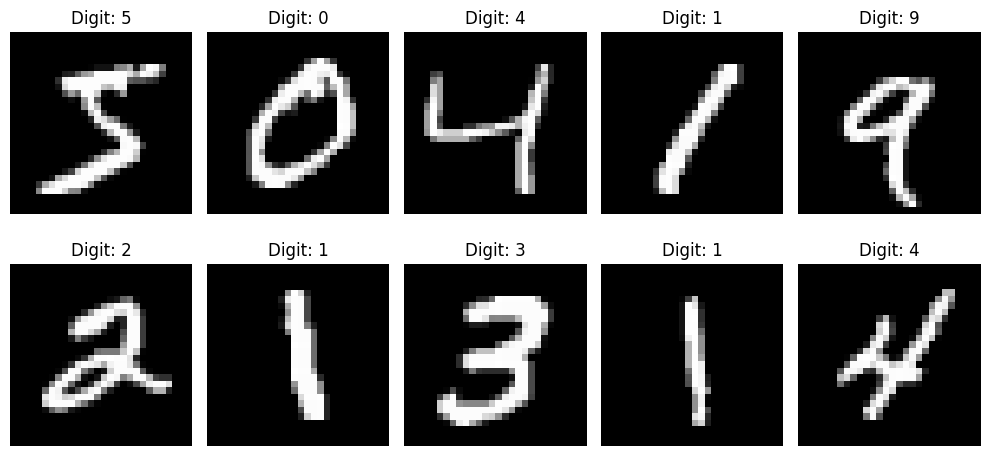

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 53ms/step - accuracy: 0.9372 - loss: 0.2058 - val_accuracy: 0.9810 - val_loss: 0.0617
Epoch 2/5
 14/844 ━━━━━━━━━━━━━━━━━━━━ 1:04 77ms/step - accuracy: 0.9720 - loss: 0.0940

In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten,
    Dense, Dropout
)

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")


# Load MNIST dataset

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training Images:", X_train.shape)
print("Testing Images:", X_test.shape)

# Normalize pixel values between 0 and 1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Reshape images for CNN
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Dataset preprocessing completed!")

#Display sample handwritten images
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


#CNN model
model = Sequential([

    Conv2D(32, (3, 3), activation='relu',
           input_shape=(28, 28, 1)),

    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),

    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dropout(0.3),

    Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

#modeltraining
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

#Check model accuracy
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")



#Display accuracy and loss graphs
plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


#Test handwritten digit predictions
predictions = model.predict(X_test[:10])

plt.figure(figsize=(12, 5))

for i in range(10):
    predicted_digit = np.argmax(predictions[i])

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {predicted_digit}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()


#Test your own handwritten digit
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded))

# Read image in grayscale
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Invert white background to black
if np.mean(img) > 127:
    img = 255 - img

# Threshold the image
_, img = cv2.threshold(
    img, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Find digit boundaries
coords = cv2.findNonZero(img)

if coords is None:
    raise ValueError("No digit detected. Upload a clearer image.")

x, y, w, h = cv2.boundingRect(coords)
digit = img[y:y+h, x:x+w]

# Resize while maintaining aspect ratio
scale = 20 / max(w, h)
new_w = max(1, int(w * scale))
new_h = max(1, int(h * scale))

digit = cv2.resize(digit, (new_w, new_h))

# Place digit in a 28x28 black canvas
canvas = np.zeros((28, 28), dtype=np.uint8)

x_offset = (28 - new_w) // 2
y_offset = (28 - new_h) // 2

canvas[y_offset:y_offset+new_h,
       x_offset:x_offset+new_w] = digit

# Normalize and predict
input_image = canvas.astype("float32") / 255.0
input_image = input_image.reshape(1, 28, 28, 1)

prediction = model.predict(input_image)
predicted_digit = np.argmax(prediction)

print("Predicted Digit:", predicted_digit)
print("Confidence:", round(float(np.max(prediction))*100, 2), "%")

plt.imshow(canvas, cmap='gray')
plt.title(f"Predicted Digit: {predicted_digit}")
plt.axis('off')
plt.show()


#Saving trained model
model.save("handwritten_digit_model.keras")

print("Model saved successfully!")

# Download trained model
files.download("handwritten_digit_model.keras")